
# 🌍 Climate & Health Risk Prediction Challenge - Starter Notebook (with Climate Enrichment)

Welcome to the starter notebook for this challenge.

In this challenge, your goal is to build a machine learning model that predicts whether a recorded death falls into a **climate-sensitive category**.

This notebook shows a baseline workflow that combines:

- the main competition data (`Train.csv`, `Test.csv`)
- the downloaded climate and environmental features (`climate_features_rich.csv`)

The notebook covers:

- Loading and merging the datasets
- Exploratory data analysis
- Preprocessing and feature engineering
- Training a baseline classifier
- Evaluating with the official metric:
  - **Final Score = 0.60 × F1 + 0.40 × ROC-AUC**
- Creating a submission file with the required columns:
  - `ID`
  - `TargetF1`
  - `TargetRAUC`

This notebook is designed to be beginner-friendly. You are encouraged to improve it with stronger models, richer feature engineering, and better validation.


In [1]:

# 📚 Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)


In [2]:

# 📥 Load the main competition data
train = pd.read_csv("Train.csv")
test = pd.read_csv("Test.csv")

# 📥 Load downloaded climate/environmental features
# This file should contain one row per ID
climate_features = pd.read_csv("climate_features.csv")

ID_COL = "ID"
TARGET = "is_climate_sensitive"
TARGET_F1 = "TargetF1"
TARGET_RAUC = "TargetRAUC"

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Climate feature shape:", climate_features.shape)

train.head()


Train shape: (3146, 13)
Test shape: (1030, 12)
Climate feature shape: (4176, 18)


,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive
0,ID_1FE951BD,Rural,Male,2007-10-02,30.0,21.137037,25.569017,18.451642,0.951601,0.584646,33.546344,"Izimba, Iganga, Uganda",1
1,ID_5927A443,Rural,Male,2008-01-05,2.0,24.062790,29.312026,18.977212,0.053352,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1
2,ID_C4E67025,Rural,Female,2008-02-14,31.0,22.407868,26.746058,18.112977,0.090349,0.573420,33.483655,"Buluza, Iganga, Uganda",1
3,ID_44DC5CE9,Rural,Female,2008-02-15,1.0,23.315198,28.056889,18.955708,0.286814,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1
4,ID_33C677BB,Rural,Female,2008-02-15,69.0,23.315198,28.056889,18.955708,0.286814,1.072343,34.226647,"Magada, Mbale City, Bugisa sub-region, Eastern...",0


In [3]:
test.head()

,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location
0,ID_E760D84B,Rural,Female,2007-11-24,75.0,21.224387,24.632729,18.145633,4.295335,0.616667,33.500000,"Buseyi, Iganga, Uganda"
1,ID_6EDEA907,Rural,Female,2008-01-23,50.0,21.708596,25.184528,18.285274,1.376196,0.725422,33.098845,"Bubago, Kamuli, Uganda"
2,ID_B9FFC8D8,Rural,Female,2008-03-14,76.0,21.371149,24.584523,18.866490,2.336643,0.603194,33.542370,"Busowobi Central, Iganga, Uganda"
3,ID_74C6C94E,Peri_urban,Female,2008-04-16,90.0,21.341990,25.188662,17.998317,4.703071,-0.590211,30.056939,"Kayanga, Mitooma, Western Region, Uganda"
4,ID_0E02825D,Rural,Male,2008-04-21,8.0,19.710391,22.905167,18.082628,4.066863,0.603194,33.542370,"Busowobi Central, Iganga, Uganda"


In [4]:
climate_features.head()

,ID,deathdate,elevation,hot_days_30d,max_daily_rain_30d,ndvi_30d,ndvi_90d,rain_days_30d,rain_sum_30d,rain_sum_7d,rain_sum_90d,slope,tavg_30d,tavg_7d,tavg_90d,temp_range_mean_30d,tmax_30d,tmin_30d
0,ID_1FE951BD,2007-10-02,1114,0,20.394434,0.72205,0.72910,18,175.264057,28.419111,421.992750,0.168545,21.425953,22.012127,21.043539,7.897970,27.608331,16.132043
1,ID_5927A443,2008-01-05,1145,0,16.994602,0.60815,0.66985,7,71.885960,0.000000,268.439276,0.299996,22.129209,23.021381,21.992129,8.735769,29.251932,15.591455
2,ID_C4E67025,2008-02-14,1145,0,15.661628,0.59290,0.61335,20,108.145379,35.970423,242.081887,0.299996,21.990516,21.557252,22.220307,7.694241,29.083597,17.420068
3,ID_44DC5CE9,2008-02-15,1145,0,15.661628,0.59290,0.61335,19,98.524518,29.091067,229.370640,0.299996,22.032392,21.693581,22.231408,7.718027,29.083597,17.420068
4,ID_33C677BB,2008-02-15,1660,0,13.468142,0.53380,0.71580,13,84.030272,25.698621,186.079130,5.565486,20.143552,20.141416,20.510054,10.152887,28.300394,12.632257



## 🔗 Merge climate features

We merge the downloaded climate and environmental features back into the training and test data using `ID`.


In [5]:
## Drop deathdate from climate_features
climate_features = climate_features.drop(columns=["deathdate"])

In [6]:

# Merge on ID
train = train.merge(climate_features, on=ID_COL, how="left")
test = test.merge(climate_features, on=ID_COL, how="left")

print("Train shape after merge:", train.shape)
print("Test shape after merge:", test.shape)

# Create a sample submission template from the test IDs
sample_submission = pd.DataFrame({
    ID_COL: test[ID_COL],
    TARGET_F1: 0,
    TARGET_RAUC: 0.5
})

sample_submission.head()


Train shape after merge: (3146, 29)
Test shape after merge: (1030, 28)


,ID,TargetF1,TargetRAUC
0,ID_E760D84B,0,0.5
1,ID_6EDEA907,0,0.5
2,ID_B9FFC8D8,0,0.5
3,ID_74C6C94E,0,0.5
4,ID_0E02825D,0,0.5



## 🔍 Exploratory Data Analysis (EDA)

Let’s inspect the merged training data, check missing values, and understand the target distribution.


In [7]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3146 entries, 0 to 3145
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    3146 non-null   object 
 1   zone                  3146 non-null   object 
 2   gender                3146 non-null   object 
 3   deathdate             3146 non-null   object 
 4   age                   3146 non-null   float64
 5   avg_temperature       3146 non-null   float64
 6   max_temperature       3146 non-null   float64
 7   min_temperature       3146 non-null   float64
 8   precipitation         3146 non-null   float64
 9   latitude              3146 non-null   float64
 10  longitude             3146 non-null   float64
 11  location              3146 non-null   object 
 12  is_climate_sensitive  3146 non-null   int64  
 13  elevation             3146 non-null   int64  
 14  hot_days_30d          3146 non-null   int64  
 15  max_daily_rain_30d   

In [8]:

# Missing values summary
missing_summary = train.isnull().sum().sort_values(ascending=False)
missing_summary[missing_summary > 0].head(30)


Series([], dtype: int64)

No missing value

In [9]:

# Target distribution
train[TARGET].value_counts(normalize=True)


is_climate_sensitive
1    0.650668
0    0.349332
Name: proportion, dtype: float64

In [10]:
train[TARGET].value_counts()

is_climate_sensitive
1    2047
0    1099
Name: count, dtype: int64

In [11]:

sns.countplot(x=TARGET, data=train)
plt.title("Target Distribution")
plt.show()


<Figure size 640x480 with 1 Axes>

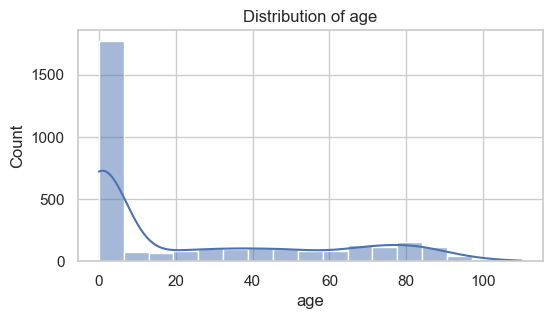

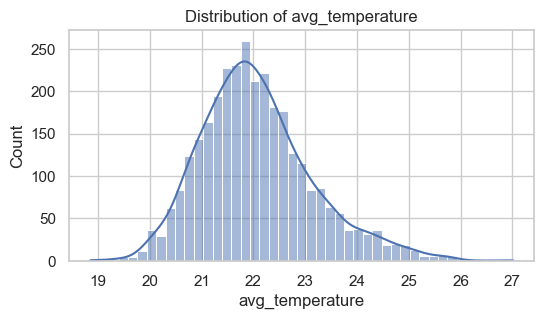

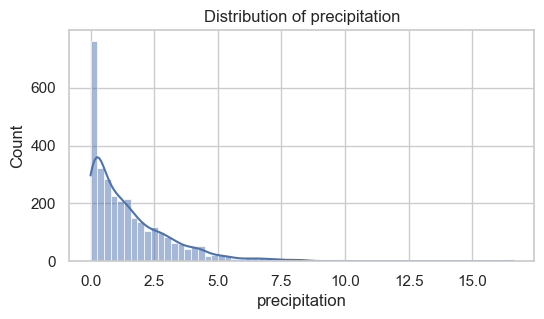

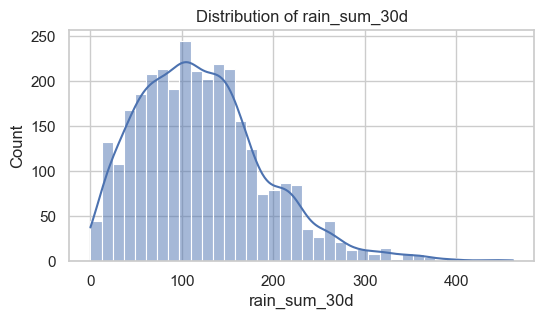

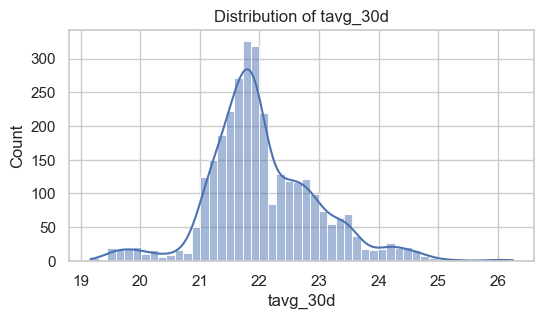

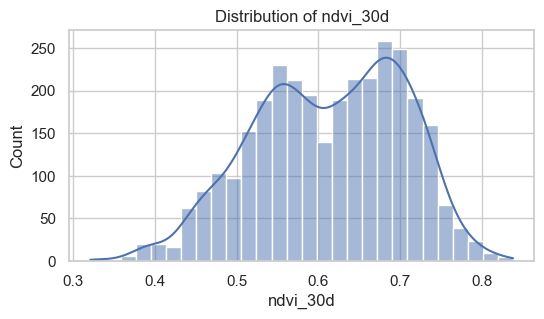

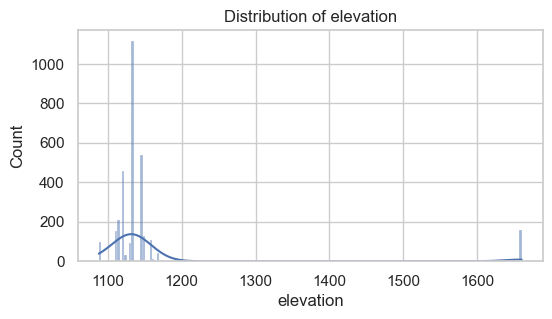

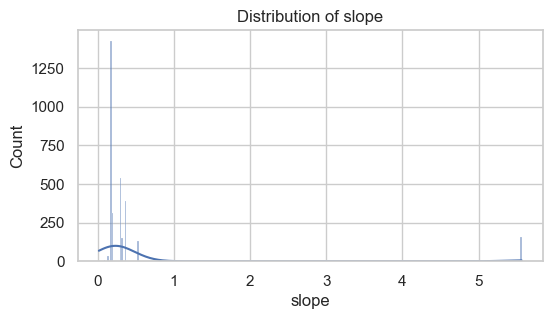

In [12]:

# Inspect some original and downloaded climate features
features_to_plot = [
    "age",
    "avg_temperature",
    "precipitation",
    "rain_sum_30d",
    "tavg_30d",
    "ndvi_30d",
    "elevation",
    "slope"
]

for col in features_to_plot:
    if col in train.columns:
        plt.figure(figsize=(6, 3))
        sns.histplot(train[col].dropna(), kde=True)
        plt.title(f"Distribution of {col}")
        plt.show()


## Lets try split the distribution plot between Yes and No

Check if there are difference in distribution between class

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


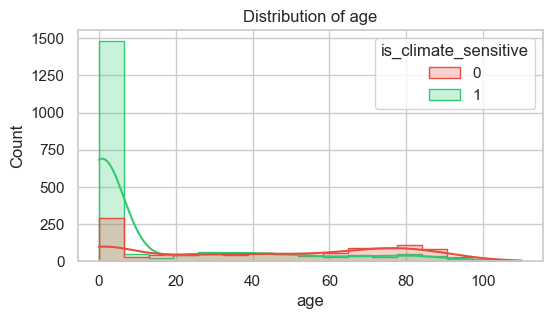

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


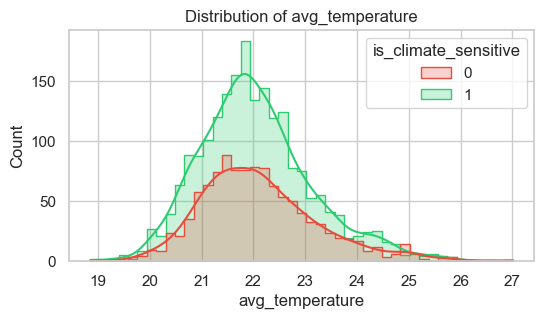

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


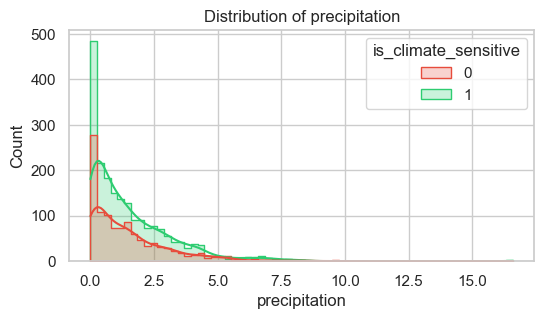

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


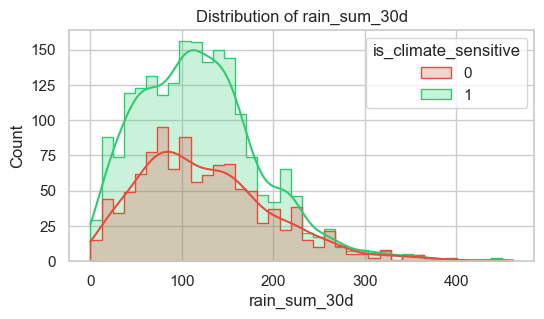

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


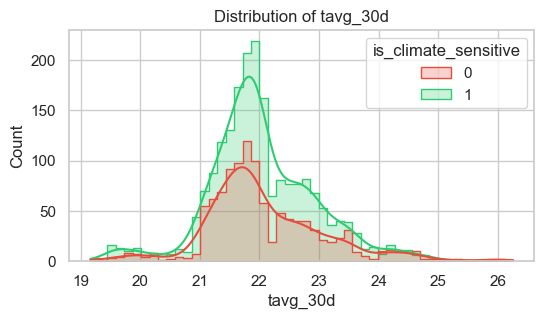

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


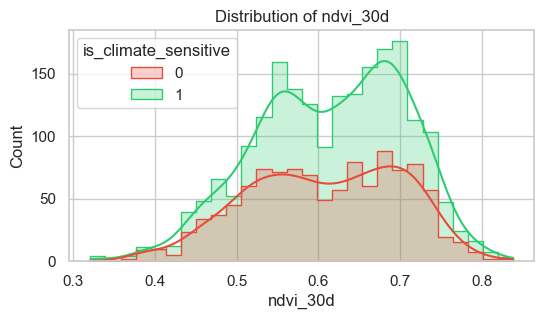

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


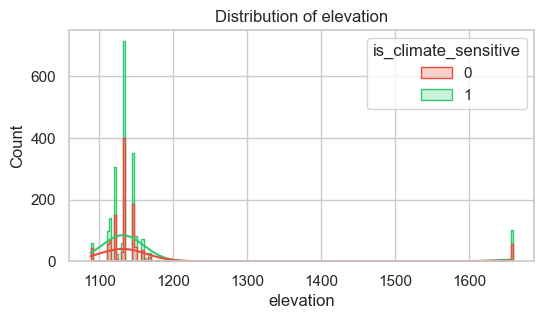

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


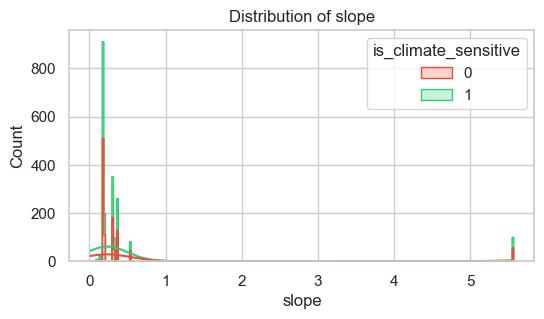

In [13]:
# Inspect some original and downloaded climate features
features_to_plot = [
    "age",
    "avg_temperature",
    "precipitation",
    "rain_sum_30d",
    "tavg_30d",
    "ndvi_30d",
    "elevation",
    "slope"
]

for col in features_to_plot:
    if col in train.columns:
        plt.figure(figsize=(6, 3))
        sns.histplot(
            data=train.dropna(subset=[col]),
            x=col,
            hue=TARGET,
            palette={1: "#2ecc71", 0: "#e74c3c"},  # Custom green/red colors
            kde=True,
            element="step",  # Clear visual distinction between overlapping distributions
        )
        plt.title(f"Distribution of {col}")
        plt.show()


In [14]:
# check column not yet checked in the observation
# numeric column
num_cols = train.select_dtypes(include=np.number).columns
num_cols

Index(['age', 'avg_temperature', 'max_temperature', 'min_temperature',
       'precipitation', 'latitude', 'longitude', 'is_climate_sensitive',
       'elevation', 'hot_days_30d', 'max_daily_rain_30d', 'ndvi_30d',
       'ndvi_90d', 'rain_days_30d', 'rain_sum_30d', 'rain_sum_7d',
       'rain_sum_90d', 'slope', 'tavg_30d', 'tavg_7d', 'tavg_90d',
       'temp_range_mean_30d', 'tmax_30d', 'tmin_30d'],
      dtype='object')

In [15]:
cat_cols = train.select_dtypes(include=['object']).columns
cat_cols

Index(['ID', 'zone', 'gender', 'deathdate', 'location'], dtype='object')

In [16]:
# plot numeric column that not yet plotted
'''
features_to_plot = [
    "age",
    "avg_temperature",
    "precipitation",
    "rain_sum_30d",
    "tavg_30d",
    "ndvi_30d",
    "elevation",
    "slope"
]
'''
features_to_plot_num = [
    #'age', 
    #'avg_temperature', 
    'max_temperature', 
    'min_temperature',
    #'precipitation', 
    #'latitude', 
    #'longitude', 
    #'is_climate_sensitive',
    #'elevation', 
    #'hot_days_30d', -- include in categorical variable
    'max_daily_rain_30d', 
    #'ndvi_30d',
    'ndvi_90d', 
    'rain_days_30d', 
    #'rain_sum_30d', 
    'rain_sum_7d',
    'rain_sum_90d', 
    #'slope', 
    #'tavg_30d', 
    'tavg_7d', 
    'tavg_90d',
    'temp_range_mean_30d', 
    'tmax_30d', 
    'tmin_30d'
]


C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


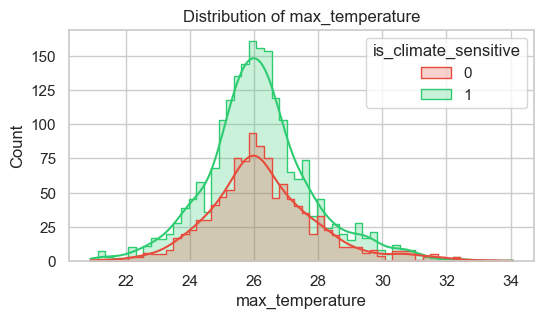

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


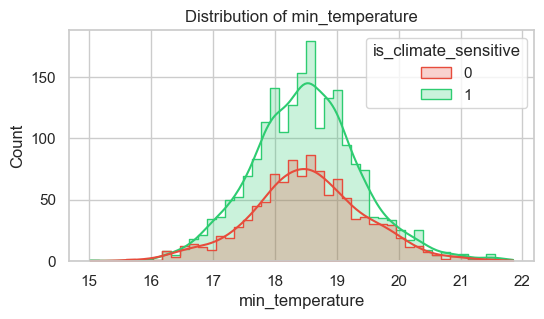

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


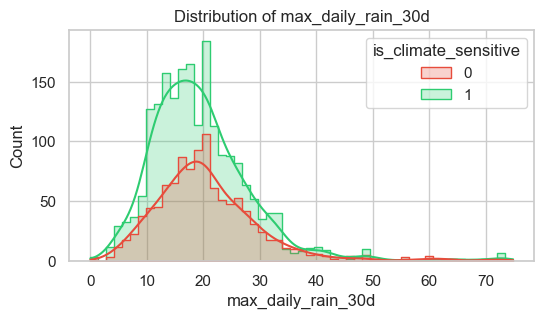

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


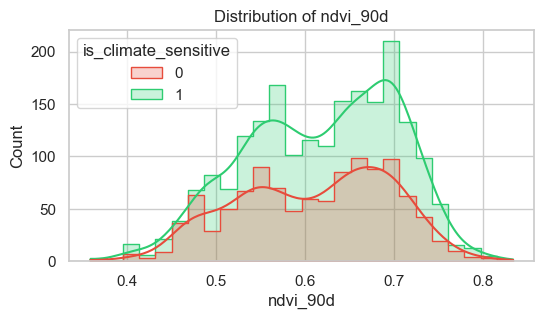

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


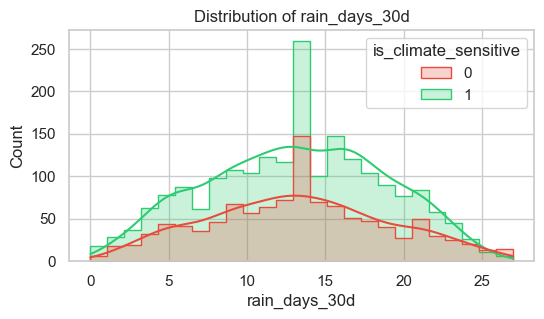

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


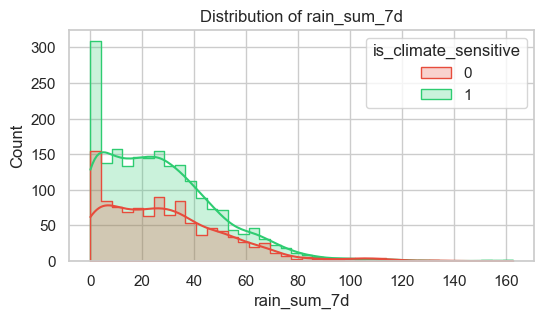

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


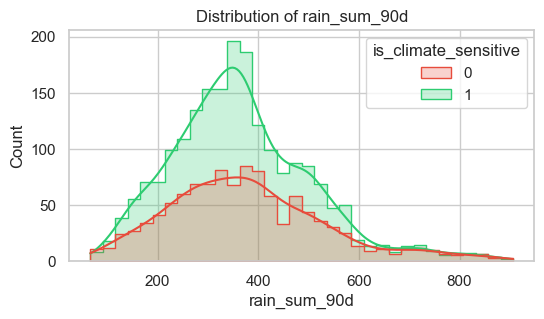

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


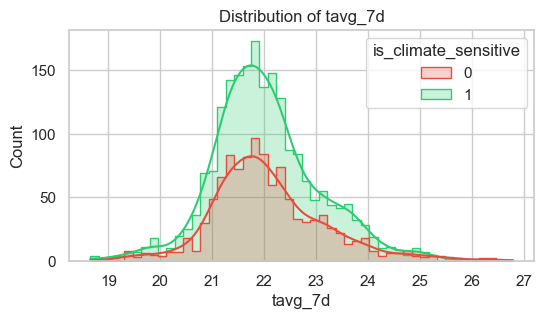

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


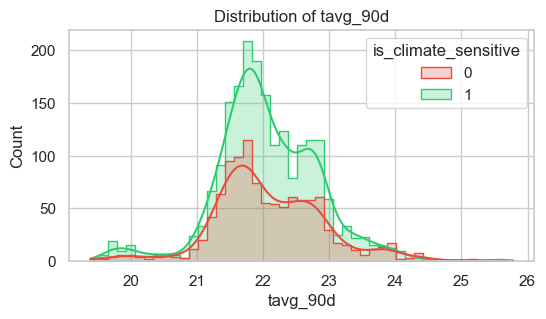

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


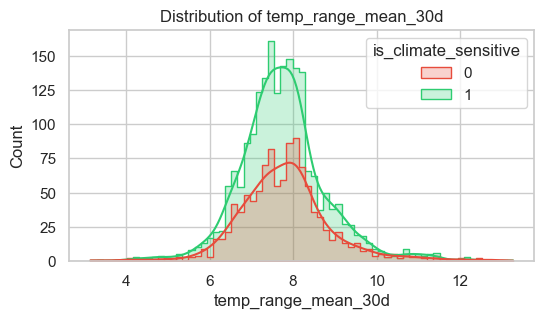

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


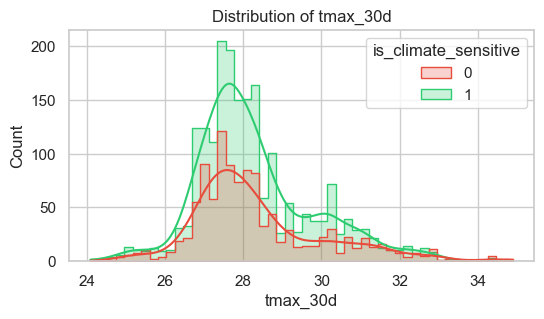

C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\User\miniconda3\envs\climate-risk\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


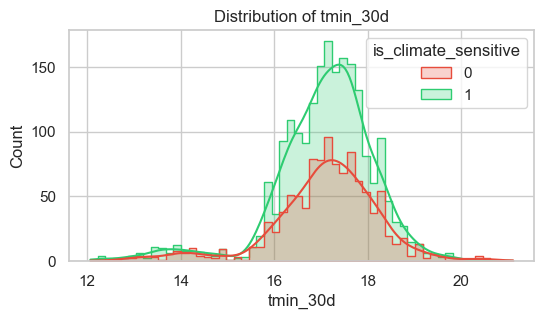

In [17]:
for col in features_to_plot_num:
    if col in train.columns:
        plt.figure(figsize=(6, 3))
        sns.histplot(
            data=train.dropna(subset=[col]),
            x=col,
            hue=TARGET,
            palette={1: "#2ecc71", 0: "#e74c3c"},  # Custom green/red colors
            kde=True,
            element="step",  # Clear visual distinction between overlapping distributions
        )
        plt.title(f"Distribution of {col}")
        plt.show()


## Histrogram of Categorical Variable

In [18]:
cat_cols

Index(['ID', 'zone', 'gender', 'deathdate', 'location'], dtype='object')

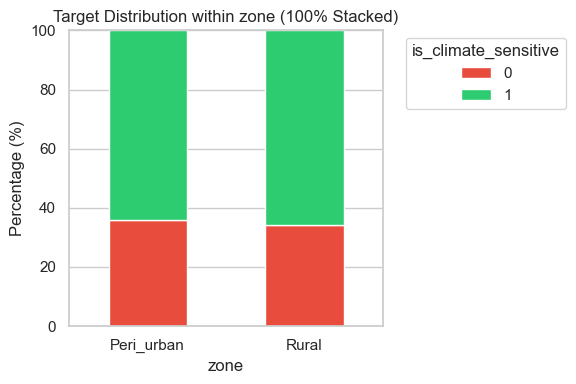

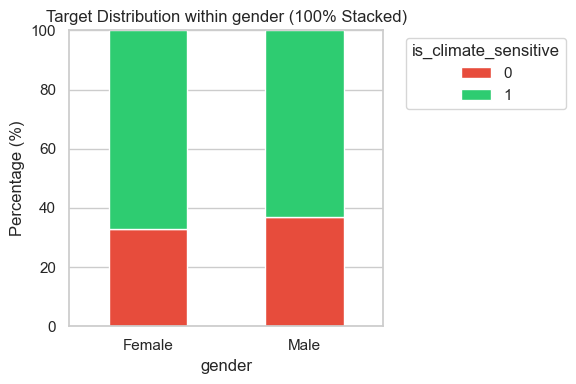

C:\Users\User\AppData\Local\Temp\ipykernel_11656\1360216416.py:34: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


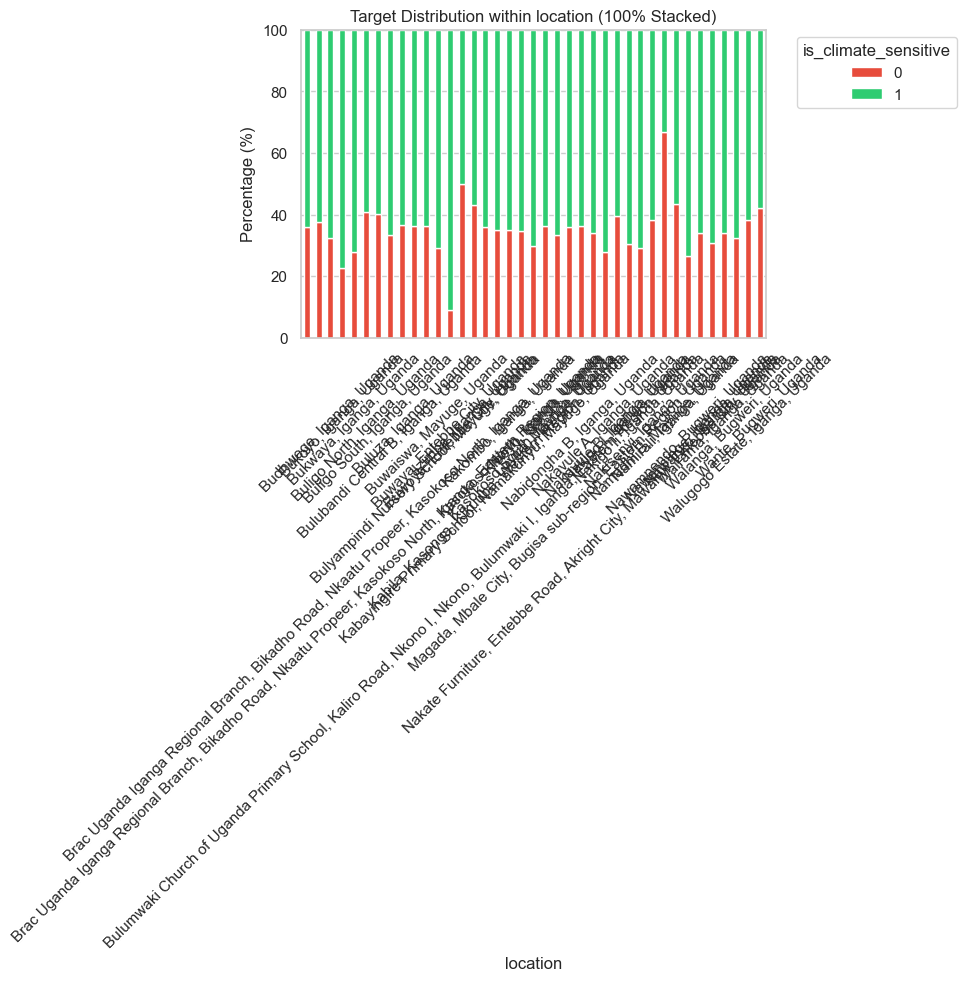

In [19]:
features_to_plot_cat =[
    #'ID', 
    'zone', 
    'gender', 
    #'deathdate', 
    'location'
]

for col in features_to_plot_cat:
    if col in train.columns:
        # Calculate percentage cross-tabulation (sums to 100% per category level)
        df_pct = (
            pd.crosstab(
                train[col], 
                train[TARGET], 
                normalize="index"
            ) * 100
        )

        # Plot stacked bar chart
        ax = df_pct.plot(
            kind="bar", 
            stacked=True, 
            figsize=(6, 4), 
            color={1: "#2ecc71", 0: "#e74c3c"}
        )
        
        plt.title(f"Target Distribution within {col} (100% Stacked)")
        plt.xlabel(col)
        plt.ylabel("Percentage (%)")
        plt.ylim(0, 100)
        plt.xticks(rotation=45 if train[col].nunique() > 5 else 0)
        plt.legend(title=TARGET, bbox_to_anchor=(1.05, 1), loc="upper left")
        plt.tight_layout()
        plt.show()

## Showing Location Crosstab 

In [20]:
location_xtab = pd.crosstab(train['location'], train[TARGET], normalize='index')

location_xtab

is_climate_sensitive,0,1
location,,
"Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Eastern Region, Uganda",0.360190,0.639810
"Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Uganda",0.376812,0.623188
"Budhwege, Iganga, Uganda",0.325000,0.675000
"Bukoyo, Iganga, Uganda",0.225806,0.774194
"Bukwaya, Iganga, Uganda",0.278481,0.721519
"Buligo North, Iganga, Uganda",0.407407,0.592593
"Buligo South, Iganga, Uganda",0.402062,0.597938
"Bulubandi Central B, Iganga, Uganda",0.333333,0.666667
"Bulumwaki Church of Uganda Primary School, Kaliro Road, Nkono I, Nkono, Bulumwaki I, Iganga, Eastern Region, Uganda",0.367742,0.632258


## Plotting Heatmap of Longitude and Latitude

In [30]:
df = train[["latitude","longitude","is_climate_sensitive"]]

In [26]:
df.head()

,latitude,longitude,is_climate_sensitive
0,0.584646,33.546344,1
1,0.549565,33.490326,1
2,0.573420,33.483655,1
3,0.549565,33.490326,1
4,1.072343,34.226647,0


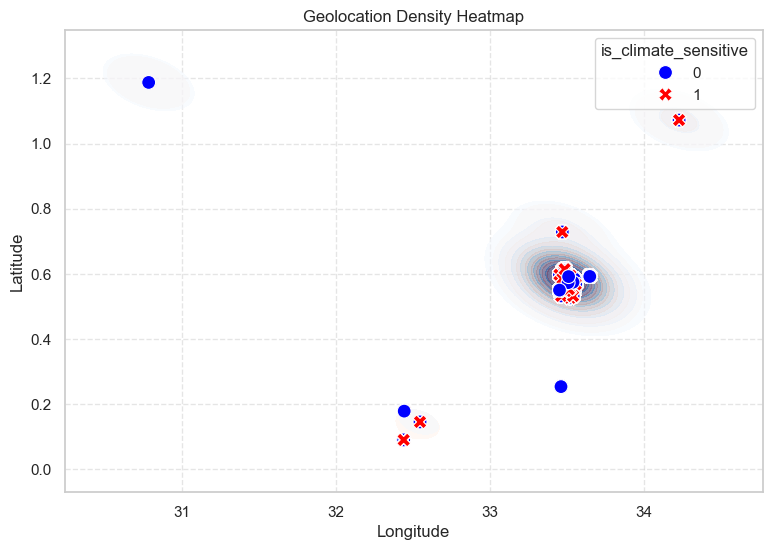

In [27]:
fig, ax = plt.subplots(figsize=(9, 6))

# Heatmap for is_climate_sensitive = 1 (Red)
sns.kdeplot(
    data=df[df['is_climate_sensitive'] == 1],
    x='longitude', y='latitude',
    cmap='Reds', fill=True, alpha=0.5, thresh=0.05, ax=ax
)

# Heatmap for is_climate_sensitive = 0 (Blue)
sns.kdeplot(
    data=df[df['is_climate_sensitive'] == 0],
    x='longitude', y='latitude',
    cmap='Blues', fill=True, alpha=0.5, thresh=0.05, ax=ax
)

# Plot point markers
sns.scatterplot(
    data=df, x='longitude', y='latitude',
    hue='is_climate_sensitive', palette={1: 'red', 0: 'blue'},
    style='is_climate_sensitive', s=100, ax=ax
)

plt.title('Geolocation Density Heatmap')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [35]:
df.to_csv("data_heatmap.csv")

In [29]:
# testing code
import folium
from folium.plugins import HeatMap
import pandas as pd

# Sample data: Latitude, Longitude, and a class/weight value
data = {
    'lat': [-6.2088, -6.2200, -6.1900, -6.2100],
    'lon': [106.8456, 106.8600, 106.8300, 106.8500],
    'weight': [0.9, 0.4, 0.7, 0.5]  # Represents class intensity or density
}
df = pd.DataFrame(data)

# Create a base map centered around the coordinates
base_map = folium.Map(location=[-6.2088, 106.8456], zoom_start=13)

# Extract lat, lon, and weight columns as a list
heat_data = df[['lat', 'lon', 'weight']].values.tolist()

# Add the heatmap layer to the map
HeatMap(heat_data).add_to(base_map)

# Save the map to an HTML file
base_map.save('geolocation_heatmap.html')


In [34]:
# map in Uganda
base_map = folium.Map(location=[1.3733, 32.2903], zoom_start=7)

# Extract lat, lon, and weight columns as a list
heat_data = df[['latitude', 'longitude', 'is_climate_sensitive']].values.tolist()

# Add the heatmap layer to the map
HeatMap(heat_data).add_to(base_map)

# Save the map to an HTML file
base_map.save('geolocation_heatmap_uganda.html')

In [38]:
# 2. Initialize the base map centered on the mean coordinates of your data
# This dynamically centers the map exactly where your points are located
map_center = [df["latitude"].mean(), df["longitude"].mean()]
base_map = folium.Map(location=map_center, zoom_start=8)

# 3. Filter data for Value 1 (Climate Sensitive)
# Gradient goes from transparent to Red
df_sensitive = df[df["is_climate_sensitive"] == 1]
heat_data_1 = df_sensitive[["latitude", "longitude"]].values.tolist()

layer_1 = folium.FeatureGroup(name="Climate Sensitive (Value 1)")
HeatMap(
    heat_data_1,
    gradient={0.4: "blue", 0.65: "orange", 1: "red"},
    radius=25,
    blur=15,
).add_to(layer_1)
layer_1.add_to(base_map)

# 4. Filter data for Value 0 (Not Climate Sensitive)
# Gradient goes from transparent to Green
df_not_sensitive = df[df["is_climate_sensitive"] == 0]
heat_data_0 = df_not_sensitive[["latitude", "longitude"]].values.tolist()

layer_0 = folium.FeatureGroup(name="Not Climate Sensitive (Value 0)")
HeatMap(
    heat_data_0,
    gradient={0.4: "blue", 0.65: "orange", 1: "red"},
    radius=25,
    blur=15,
).add_to(layer_0)
layer_0.add_to(base_map)

# 5. Add a Layer Control panel to turn classes on and off
folium.LayerControl(collapsed=False).add_to(base_map)

# 6. Save the interactive map
base_map.save("uganda_classified_heatmap.html")
print("Map successfully created as 'uganda_classified_heatmap.html'!")

Map successfully created as 'uganda_classified_heatmap.html'!


**Using heatmap doesn't seem promising**

The value is not very different. Lets create code to split and get the location

In [44]:
locate = location_xtab.reset_index()

In [46]:
# location_xtab.to_csv("location_city.csv")
locate["city"] = locate["location"].apply(lambda x: x.split(',')[0])

In [47]:
locate

is_climate_sensitive,location,0,1,city
0,"Brac Uganda Iganga Regional Branch, Bikadho Ro...",0.360190,0.639810,Brac Uganda Iganga Regional Branch
1,"Brac Uganda Iganga Regional Branch, Bikadho Ro...",0.376812,0.623188,Brac Uganda Iganga Regional Branch
2,"Budhwege, Iganga, Uganda",0.325000,0.675000,Budhwege
3,"Bukoyo, Iganga, Uganda",0.225806,0.774194,Bukoyo
4,"Bukwaya, Iganga, Uganda",0.278481,0.721519,Bukwaya
5,"Buligo North, Iganga, Uganda",0.407407,0.592593,Buligo North
6,"Buligo South, Iganga, Uganda",0.402062,0.597938,Buligo South
7,"Bulubandi Central B, Iganga, Uganda",0.333333,0.666667,Bulubandi Central B
8,"Bulumwaki Church of Uganda Primary School, Kal...",0.367742,0.632258,Bulumwaki Church of Uganda Primary School
9,"Buluza, Iganga, Uganda",0.364583,0.635417,Buluza


## Idea while looking at the distribution

**a. Maybe I could binned age. Reason, when the age is young, most probably died due to the climate, while when old, die naturally. In the middle, could be both. Binning into three?**
Ide binning:\
. <15\
. 15 - 55\
. >55

**b. Distribution of rain in 7d. Sepertinya bisa di bin juga**
bin\
.<=5\
.>5

**c. Distribution of rain 90d. Bisa di bin juga**
bin\
.350-400
.Other

**d. Urban and non urban not really useful - DONE**

**e. Gender and Country are useful features - DONE**

**f. Is everything happened in Uganda - DONE**

**g. Extract common location: Iganga, Bukweri - DONE**

**h. Clustering by the geolocation**

**i. Check if month have correlation with death - Check below**

In [49]:
train["city"] = train["location"].apply(lambda x: x.split(',')[0])

In [51]:
# Convert dates
train["deathdate"] = pd.to_datetime(train["deathdate"], errors="coerce")
test["deathdate"] = pd.to_datetime(test["deathdate"], errors="coerce")

In [57]:
train["month"]= train["deathdate"].dt.month_name()
train["month_num"]= train["deathdate"].dt.month

In [58]:
train.head()

,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive,elevation,hot_days_30d,max_daily_rain_30d,ndvi_30d,ndvi_90d,rain_days_30d,rain_sum_30d,rain_sum_7d,rain_sum_90d,slope,tavg_30d,tavg_7d,tavg_90d,temp_range_mean_30d,tmax_30d,tmin_30d,city,month,month_num
0,ID_1FE951BD,Rural,Male,2007-10-02,30.0,21.137037,25.569017,18.451642,0.951601,0.584646,33.546344,"Izimba, Iganga, Uganda",1,1114,0,20.394434,0.72205,0.72910,18,175.264057,28.419111,421.992750,0.168545,21.425953,22.012127,21.043539,7.897970,27.608331,16.132043,Izimba,October,10
1,ID_5927A443,Rural,Male,2008-01-05,2.0,24.062790,29.312026,18.977212,0.053352,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1,1145,0,16.994602,0.60815,0.66985,7,71.885960,0.000000,268.439276,0.299996,22.129209,23.021381,21.992129,8.735769,29.251932,15.591455,Nawanzu,January,1
2,ID_C4E67025,Rural,Female,2008-02-14,31.0,22.407868,26.746058,18.112977,0.090349,0.573420,33.483655,"Buluza, Iganga, Uganda",1,1145,0,15.661628,0.59290,0.61335,20,108.145379,35.970423,242.081887,0.299996,21.990516,21.557252,22.220307,7.694241,29.083597,17.420068,Buluza,February,2
3,ID_44DC5CE9,Rural,Female,2008-02-15,1.0,23.315198,28.056889,18.955708,0.286814,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1,1145,0,15.661628,0.59290,0.61335,19,98.524518,29.091067,229.370640,0.299996,22.032392,21.693581,22.231408,7.718027,29.083597,17.420068,Nawanzu,February,2
4,ID_33C677BB,Rural,Female,2008-02-15,69.0,23.315198,28.056889,18.955708,0.286814,1.072343,34.226647,"Magada, Mbale City, Bugisa sub-region, Eastern...",0,1660,0,13.468142,0.53380,0.71580,13,84.030272,25.698621,186.079130,5.565486,20.143552,20.141416,20.510054,10.152887,28.300394,12.632257,Magada,February,2


In [56]:
month_xtab = pd.crosstab(train['month'], train[TARGET], normalize='index')

month_xtab

is_climate_sensitive,0,1
month,,
April,0.321429,0.678571
August,0.358779,0.641221
December,0.368794,0.631206
February,0.349398,0.650602
January,0.306513,0.693487
July,0.334545,0.665455
June,0.347134,0.652866
March,0.403433,0.596567
May,0.337705,0.662295


In [59]:
month_num_xtab = pd.crosstab(train['month_num'], train[TARGET], normalize='index')

month_num_xtab

is_climate_sensitive,0,1
month_num,,
1,0.306513,0.693487
2,0.349398,0.650602
3,0.403433,0.596567
4,0.321429,0.678571
5,0.337705,0.662295
6,0.347134,0.652866
7,0.334545,0.665455
8,0.358779,0.641221
9,0.387665,0.612335


### To do

1. Create age binning
2. Create rain 7d binning
3. create rain 90d binning
4. Create common location


## 🧹 Preprocessing and feature engineering

We keep the baseline simple and use:

- the original challenge features
- the downloaded climate/environmental features
- a few easy engineered features from `deathdate`


In [10]:

train_df = train.copy()
test_df = test.copy()

# Convert dates
train_df["deathdate"] = pd.to_datetime(train_df["deathdate"], errors="coerce")
test_df["deathdate"] = pd.to_datetime(test_df["deathdate"], errors="coerce")

# Simple date features
for df_ in [train_df, test_df]:
    df_["day_of_year"] = df_["deathdate"].dt.dayofyear
    df_["temperature_range"] = df_["max_temperature"] - df_["min_temperature"]
    df_["is_rainy_day_current"] = (df_["precipitation"] > 0).astype(int)

# Drop raw date after feature extraction
train_df = train_df.drop(columns=["deathdate"])
test_df = test_df.drop(columns=["deathdate"])

train_df.head()


,ID,zone,gender,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive,elevation,hot_days_30d,max_daily_rain_30d,ndvi_30d,ndvi_90d,rain_days_30d,rain_sum_30d,rain_sum_7d,rain_sum_90d,slope,tavg_30d,tavg_7d,tavg_90d,temp_range_mean_30d,tmax_30d,tmin_30d,day_of_year,temperature_range,is_rainy_day_current
0,ID_1FE951BD,Rural,Male,30.0,21.137037,25.569017,18.451642,0.951601,0.584646,33.546344,"Izimba, Iganga, Uganda",1,1114,0,20.394434,0.72205,0.72910,18,175.264057,28.419111,421.992750,0.168545,21.425953,22.012127,21.043539,7.897970,27.608331,16.132043,275,7.117375,1
1,ID_5927A443,Rural,Male,2.0,24.062790,29.312026,18.977212,0.053352,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1,1145,0,16.994602,0.60815,0.66985,7,71.885960,0.000000,268.439276,0.299996,22.129209,23.021381,21.992129,8.735769,29.251932,15.591455,5,10.334814,1
2,ID_C4E67025,Rural,Female,31.0,22.407868,26.746058,18.112977,0.090349,0.573420,33.483655,"Buluza, Iganga, Uganda",1,1145,0,15.661628,0.59290,0.61335,20,108.145379,35.970423,242.081887,0.299996,21.990516,21.557252,22.220307,7.694241,29.083597,17.420068,45,8.633080,1
3,ID_44DC5CE9,Rural,Female,1.0,23.315198,28.056889,18.955708,0.286814,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1,1145,0,15.661628,0.59290,0.61335,19,98.524518,29.091067,229.370640,0.299996,22.032392,21.693581,22.231408,7.718027,29.083597,17.420068,46,9.101181,1
4,ID_33C677BB,Rural,Female,69.0,23.315198,28.056889,18.955708,0.286814,1.072343,34.226647,"Magada, Mbale City, Bugisa sub-region, Eastern...",0,1660,0,13.468142,0.53380,0.71580,13,84.030272,25.698621,186.079130,5.565486,20.143552,20.141416,20.510054,10.152887,28.300394,12.632257,46,9.101181,1


In [11]:

# Define target and features
X = train_df.drop(columns=[TARGET, ID_COL])
y = train_df[TARGET]

X_test = test_df.drop(columns=[ID_COL])

categorical_features = [c for c in X.columns if X[c].dtype == "object"]
numeric_features = [c for c in X.columns if c not in categorical_features]

print("Categorical features:", categorical_features)
print("\nNumber of numeric features:", len(numeric_features))
print("\nA few numeric features:", numeric_features[:20])


Categorical features: ['zone', 'gender', 'location']

Number of numeric features: 26

A few numeric features: ['age', 'avg_temperature', 'max_temperature', 'min_temperature', 'precipitation', 'latitude', 'longitude', 'elevation', 'hot_days_30d', 'max_daily_rain_30d', 'ndvi_30d', 'ndvi_90d', 'rain_days_30d', 'rain_sum_30d', 'rain_sum_7d', 'rain_sum_90d', 'slope', 'tavg_30d', 'tavg_7d', 'tavg_90d']



## ✂️ Train / Validation Split

We create a validation set to estimate baseline performance before generating a submission.


In [12]:

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)


X_train shape: (2516, 29)
X_val shape: (630, 29)



## 🤖 Baseline Model

We use Logistic Regression as a simple and interpretable baseline.

Because the challenge metric includes both **F1** and **ROC-AUC**, this is a good baseline model to start with before trying stronger methods such as Random Forest, LightGBM, XGBoost, or CatBoost.


In [13]:
## Drop location from categorical features
categorical_features.remove("location")
categorical_features

['zone', 'gender']

In [14]:
## Check if latitude and longitude are in numerical features and drop them
numeric_features.remove("latitude")
numeric_features.remove("longitude")
numeric_features

['age',
 'avg_temperature',
 'max_temperature',
 'min_temperature',
 'precipitation',
 'elevation',
 'hot_days_30d',
 'max_daily_rain_30d',
 'ndvi_30d',
 'ndvi_90d',
 'rain_days_30d',
 'rain_sum_30d',
 'rain_sum_7d',
 'rain_sum_90d',
 'slope',
 'tavg_30d',
 'tavg_7d',
 'tavg_90d',
 'temp_range_mean_30d',
 'tmax_30d',
 'tmin_30d',
 'day_of_year',
 'temperature_range',
 'is_rainy_day_current']

In [15]:

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        ),
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ('scaler', StandardScaler())
            ]),
            numeric_features
        )
    ]
)

pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

pipeline.fit(X_train, y_train)


Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['zone', 'gender']),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'avg_temperature',
                                                   'max_temperature',
                                                   '...
                                                   'precipitation', 'elevation',
                                                   'hot_days_30d',
                                                   'max_daily_rain_30d',
                                                   'ndvi_30d', 'ndvi_90d',
                                                   'rain_days_30d',
                                                   'rain_sum_30d',
                                                   'rain_sum_7d',
                                                   'rain_sum_90d', 'slope',
                                                   'tavg_30d', 'tavg_7d',
                                                   'tavg_90d',
                                                   'temp_range_mean_30d',
                                                   'tmax_30d', 'tmin_30d',
                                                   'day_of_year',
                                                   'temperature_range',
                                                   'is_rainy_day_current'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=2000))])


## 📈 Validation Performance

Official metric:

**Final Score = 0.60 × F1 + 0.40 × ROC-AUC**

Participants submit:
- `TargetF1`: binary prediction
- `TargetRAUC`: probability prediction


In [16]:

# Validation predictions
val_pred_proba = pipeline.predict_proba(X_val)[:, 1]
val_pred_label = (val_pred_proba >= 0.5).astype(int)

f1 = f1_score(y_val, val_pred_label)
auc = roc_auc_score(y_val, val_pred_proba)
final_score = 0.60 * f1 + 0.40 * auc

print(f"Validation F1-score: {f1:.6f}")
print(f"Validation ROC-AUC:  {auc:.6f}")
print(f"Validation Final Score: {final_score:.6f}")

print("\nClassification Report:")
print(classification_report(y_val, val_pred_label, digits=3))


Validation F1-score: 0.801944
Validation ROC-AUC:  0.781746
Validation Final Score: 0.793865

Classification Report:
              precision    recall  f1-score   support

           0      0.631     0.623     0.627       220
           1      0.799     0.805     0.802       410

    accuracy                          0.741       630
   macro avg      0.715     0.714     0.714       630
weighted avg      0.740     0.741     0.741       630



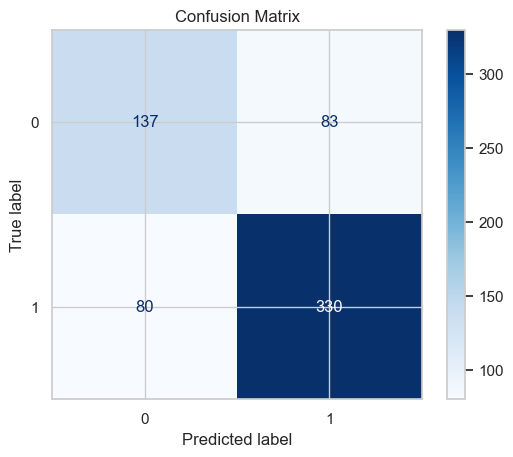

In [17]:

cm = confusion_matrix(y_val, val_pred_label)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()



## 📊 Feature Importance

We use permutation importance to see which features are most helpful to the baseline model.


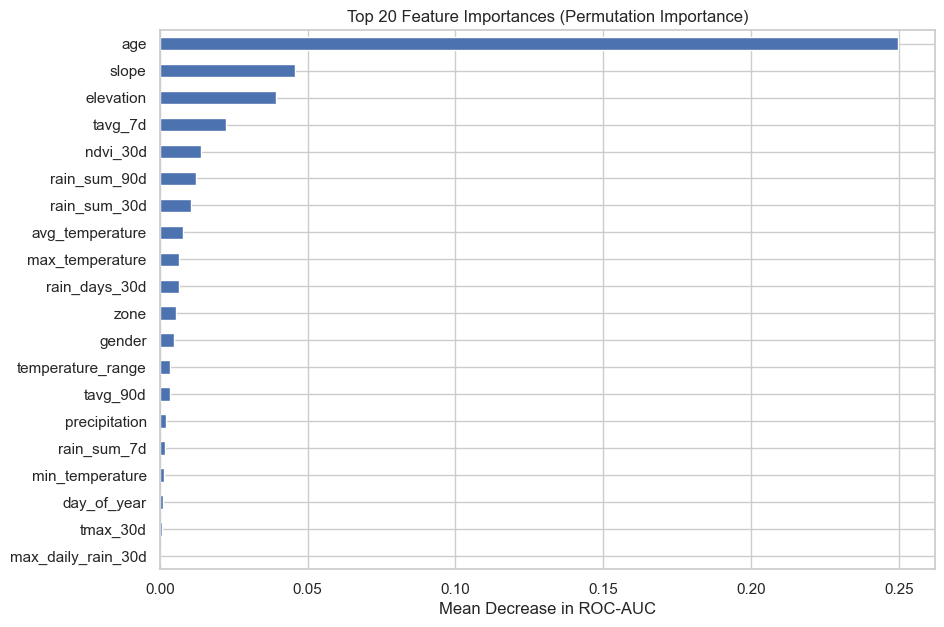

In [18]:

result = permutation_importance(
    pipeline,
    X_val,
    y_val,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
    scoring="roc_auc"
)

importances = pd.Series(result.importances_mean, index=X.columns)

(
    importances
    .sort_values(ascending=False)
    .head(20)
    .sort_values()
    .plot(kind="barh", figsize=(10, 7))
)

plt.title("Top 20 Feature Importances (Permutation Importance)")
plt.xlabel("Mean Decrease in ROC-AUC")
plt.show()



## 🚀 Train on Full Data and Predict on Test

Now retrain the baseline on the full training data and generate the submission file.


In [19]:

pipeline.fit(X, y)

test_pred_proba = pipeline.predict_proba(X_test)[:, 1]
test_pred_label = (test_pred_proba >= 0.5).astype(int)

submission = pd.DataFrame({
    ID_COL: test[ID_COL],
    TARGET_F1: test_pred_label,
    TARGET_RAUC: test_pred_proba
})

submission.head()


,ID,TargetF1,TargetRAUC
0,ID_E760D84B,0,0.192852
1,ID_6EDEA907,0,0.411029
2,ID_B9FFC8D8,0,0.239403
3,ID_74C6C94E,1,0.755378
4,ID_0E02825D,1,0.698908


In [20]:

submission.to_csv("starter_submission.csv", index=False)
print("Submission file saved as starter_submission.csv")


Submission file saved as starter_submission.csv



## ✅ What’s Next?

This is still only a starter baseline. You can improve it by:

- trying stronger models such as Random Forest, LightGBM, XGBoost, or CatBoost
- tuning the threshold used for `TargetF1`
- engineering richer spatial features
- comparing models with and without downloaded climate features
- validating more carefully across space

Good luck, and happy modelling! 🚀
